# Security concepts you can compute with

**Module 01 — Introduction to Securing AI Systems** · Securing AI Systems (BS Data Science)

This notebook turns three ideas from Module 01 into objects you can inspect: the CIA triad, trust
boundaries, and risk as impact × likelihood. Nothing here is a metaphor — each idea becomes a data
structure you can test with assertions.

## Learning objectives

By the end of this notebook you can:

1. Encode confidentiality, integrity and availability requirements as explicit, checkable values.
2. Draw a data-flow table for a small system and identify every trust-boundary crossing.
3. Compute inherent and residual risk, and explain why a control that is not measured is not a control.
4. State which of these quantities a model's accuracy metric does **not** capture.

## Background

An AI system has security requirements that exist whether or not anyone writes them down. The CIA
triad names three:

* **Confidentiality** — data and model behaviour are disclosed only to those authorised.
* **Integrity** — data, model artefacts and predictions are not altered without detection.
* **Availability** — the service answers, at an acceptable latency, when it is needed.

Module 01's central practical claim is that risk is a product of *impact* and *likelihood*, and that
a control reduces risk only if you can measure the reduction. The code below makes both claims
concrete.

## Dependencies

* Python 3.11+
* `numpy`, `pandas`, `matplotlib`

## Installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "matplotlib>=3.9"
```

No GPU, no network access and no datasets are required; every value below is generated in the
notebook. The fixed seed makes the numbers identical on every run.

In [1]:
import math
from enum import Enum

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 1
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 100)

print("rng ready with seed", SEED)

rng ready with seed 1


### Step 1 — Write the requirements down as data

A requirement that lives only in a slide cannot be tested. Here each requirement is a row: which
property it protects, which asset it covers, and what would count as a failure.

In [2]:
class Property(str, Enum):
    CONFIDENTIALITY = "confidentiality"
    INTEGRITY = "integrity"
    AVAILABILITY = "availability"


requirements = pd.DataFrame(
    [
        ("REQ-1", Property.CONFIDENTIALITY, "patient records", "any unauthorised read"),
        ("REQ-2", Property.INTEGRITY, "training labels", "any undetected relabel"),
        ("REQ-3", Property.AVAILABILITY, "triage endpoint", "p99 latency > 2 s"),
        ("REQ-4", Property.INTEGRITY, "model artefact", "unsignened weight update"),
    ],
    columns=["id", "property", "asset", "failure_condition"],
)

requirements

,id,property,asset,failure_condition
0,REQ-1,Property.CONFIDENTIALITY,patient records,any unauthorised read
1,REQ-2,Property.INTEGRITY,training labels,any undetected relabel
2,REQ-3,Property.AVAILABILITY,triage endpoint,p99 latency > 2 s
3,REQ-4,Property.INTEGRITY,model artefact,unsignened weight update


**Expected output** — a four-row table. Read column `failure_condition` as the test you would run:
each is falsifiable, which is what makes the requirement a requirement rather than a wish.

### Step 2 — Model the data flow and mark every boundary crossing

A trust boundary exists wherever data moves between two components that do not share the same
authority. The crossing itself is not a vulnerability; an *unmediated* crossing is.

In [3]:
flows = pd.DataFrame(
    [
        ("browser", "api", "prediction request", "trusted", False),
        ("api", "model server", "features", "trusted", False),
        ("vendor feed", "training pipeline", "labelled records", "untrusted", True),
        ("support inbox", "rag index", "customer emails", "untrusted", True),
        ("model server", "audit log", "prediction record", "trusted", False),
    ],
    columns=["source", "destination", "payload", "provenance", "crosses_boundary"],
)

crossings = flows[flows.crosses_boundary]
unmediated = crossings[crossings.provenance == "untrusted"]
print(f"{len(crossings)} boundary crossings, {len(unmediated)} carrying untrusted data")
unmediated

2 boundary crossings, 2 carrying untrusted data


,source,destination,payload,provenance,crosses_boundary
2,vendor feed,training pipeline,labelled records,untrusted,True
3,support inbox,rag index,customer emails,untrusted,True


**Expected output** — two crossings, both carrying untrusted data: the vendor feed and the support
inbox. Those two rows are exactly where Module 05 (data handling), 07 (poisoning) and 13 (retrieval)
will spend their attention. Module 01's lesson is that you found them by *listing flows*, not by
admiring the architecture diagram.

### Step 3 — Risk as a product, and the arithmetic of controls

For each risk we record impact (1–5) and likelihood (1–5). A control multiplies likelihood by a
residual factor that must be **justified by a measurement**, not assumed.

In [4]:
risks = pd.DataFrame(
    [
        ("R1", "poisoned vendor labels", 5, 3, 0.4, "provenance + spectral check, recall 0.77"),
        ("R2", "prompt injection in inbox", 4, 4, 0.5, "delimiting + no tools from context"),
        ("R3", "model file replaced", 5, 2, 0.1, "signature verification at load"),
        ("R4", "endpoint saturation", 2, 4, 0.6, "token quota + circuit breaker"),
    ],
    columns=["id", "risk", "impact", "likelihood", "residual_factor", "control_evidence"],
)

risks["inherent"] = risks.impact * risks.likelihood
risks["residual"] = (risks.inherent * risks.residual_factor).round(2)
risks["reduction_pct"] = (100 * (1 - risks.residual / risks.inherent)).round(0)
risks.sort_values("residual", ascending=False)

,id,risk,impact,likelihood,residual_factor,control_evidence,inherent,residual,reduction_pct
1,R2,prompt injection in inbox,4,4,0.5,delimiting + no tools from context,16,8.0,50.0
0,R1,poisoned vendor labels,5,3,0.4,"provenance + spectral check, recall 0.77",15,6.0,60.0
3,R4,endpoint saturation,2,4,0.6,token quota + circuit breaker,8,4.8,40.0
2,R3,model file replaced,5,2,0.1,signature verification at load,10,1.0,90.0


**Expected output** — R1 and R2 remain the two highest residual risks even after control. That is the
normal result: controls reduce, they do not eliminate. The `control_evidence` column is the point of
the table — a residual factor without evidence is a guess wearing a number.

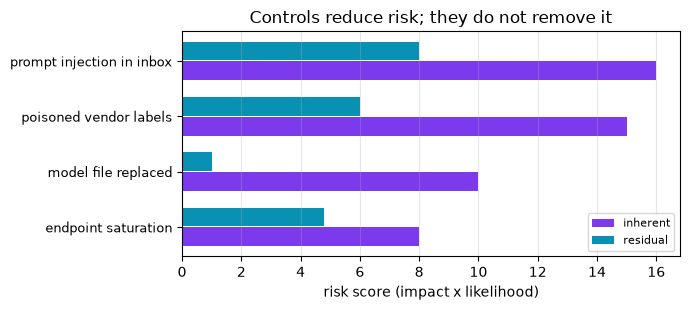

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2))
order = risks.sort_values("inherent", ascending=True)
y = np.arange(len(order))
ax.barh(y - 0.18, order.inherent, height=0.34, label="inherent", color="#7c3aed")
ax.barh(y + 0.18, order.residual, height=0.34, label="residual", color="#0891b2")
ax.set_yticks(y, order.risk, fontsize=9)
ax.set_xlabel("risk score (impact x likelihood)")
ax.set_title("Controls reduce risk; they do not remove it")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Expected output** — four paired bars. The gap between purple and teal is the claimed benefit of
each control; the teal bar is what you are accepting. If a gap is large and the evidence is thin, the
chart is fiction, which is why the evidence column sits in the same table.

### Step 4 — Check the invariants instead of trusting the table

Three assertions make the reasoning auditable. If someone later changes a residual factor without
evidence, the third assertion is where the argument breaks.

In [6]:
assert (risks.residual <= risks.inherent).all(), "a control increased risk"
assert (risks.residual_factor.between(0, 1)).all(), "residual factor outside [0, 1]"
assert risks.control_evidence.str.len().gt(10).all(), "control claimed without evidence"

highest = risks.loc[risks.residual.idxmax()]
print(f"Highest residual risk: {highest.risk} (score {highest.residual})")
print("All invariants hold. A control without evidence would fail the third assertion.")

Highest residual risk: prompt injection in inbox (score 8.0)
All invariants hold. A control without evidence would fail the third assertion.


**Expected output**

```text
Highest residual risk: prompt injection in inbox (score 8.0)
All invariants hold. A control without evidence would fail the third assertion.
```

## Exercises

1. **Add a fifth requirement.** Choose a property (for example *non-repudiation* of a prediction) and
   write its failure condition so that a test could decide it.
2. **Break an assertion.** Set `R3`'s residual factor to `1.2` and observe the failure. Explain in one
   sentence what the assertion protected you from.
3. **Add a boundary crossing** for a clinician uploading a PDF to a summariser, then decide whether it
   needs mediation and what that mediation would be.
4. **Recompute with a measurement.** Replace R1's 0.4 with 0.6 (a weaker detector) and report which
   risk becomes the largest.

## Reflection questions

1. Which is more dangerous in this system: a requirement nobody wrote down, or a control nobody
   measured? Argue both sides, then decide.
2. The table treats impact and likelihood as independent. Give a concrete case in this system where
   they are not, and say what that does to the arithmetic.
3. Module 01 claims accuracy is not a security metric. Using the tables above, identify one risk that a
   99 % accurate model would leave completely untouched.

## References

1. NIST, *AI Risk Management Framework 1.0*, NIST AI 100-1, 2023 — Govern and Map functions.
2. Saltzer, J. and Schroeder, M., "The Protection of Information in Computer Systems", 1975.
3. Shostack, A., *Threat Modeling: Designing for Security*, Wiley, 2014.
4. OWASP, *Top 10 for LLM Applications*, 2025 — LLM01, LLM03.